# Chess Style Fingerprint: Final Workflow

This notebook is the final reproducible workflow for the repository submission.

It presents and runs the two project models:

1. **Model 1: Neural stylometry / hybrid neural model**
   - Inspired by behavioral stylometry in chess.
   - Uses a padded whole-game board tensor sequence.
   - Optionally fuses 33 `style_trajectory` features.

2. **Model 2: Controlled style-trajectory classifier**
   - Uses same-FEN human-vs-Stockfish continuations.
   - Extracts interpretable style trajectory features.
   - Trains SVM and random forest classifiers.
   - Runs all available human-vs-Stockfish controlled pairs.

Important: the final Model 2 result uses `style_trajectory`, not direct Stockfish top-move agreement. The earlier `engine_agreement` feature set is kept only as a baseline/ablation.

`engine_agreement` means features that directly compare the played move with Stockfish's preferred move: exact top-move match, top-k match, centipawn loss, and related move-quality scores. This was not explained in the presentation slides because it is not one of the final models; it is included here to document the design decision. For human-vs-Stockfish classification it is partly circular, because Stockfish continuations are expected to agree with Stockfish. The final `style_trajectory` features avoid this direct move-matching signal and instead use Stockfish only to evaluate how the board position changes over time.


## 1. Setup

Run this notebook from the repository root:

```bash
cd /Users/aadil/Chess-ML-Project/chess-style-fingerprint
jupyter notebook final_workflow.ipynb
```

The notebook is designed to run all cells. If a result CSV already exists, the helper function reuses it by default. Set `FORCE_RERUN = True` to regenerate all experiment outputs.

In [1]:
from pathlib import Path
import subprocess
import json
%pip install pandas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
OUT = ROOT / "outputs"
FIG = OUT / "figures"
OUT.mkdir(exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

FORCE_RERUN = False

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

MODEL_NAMES = {
    "logreg": "Logistic",
    "svm_linear": "Linear SVM",
    "svm_rbf": "RBF SVM",
    "forest": "Random Forest",
    "gbdt": "Gradient Boosting",
    "mlp": "MLP",
    "knn": "KNN",
}
MODEL_ORDER = ["logreg", "svm_linear", "svm_rbf", "forest", "gbdt", "mlp", "knn"]
REPORT_MODELS = ["svm_linear", "svm_rbf", "forest"]


def run_command(cmd, output_path=None, force=False):
    output_path = Path(output_path) if output_path else None
    if output_path and output_path.exists() and not force:
        print(f"Using existing {output_path}")
        return
    print("Running:", " ".join(cmd))
    subprocess.run(cmd, check=True)


def read_csv(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}")
    return pd.read_csv(path)


def metric(row, model, metric_name):
    key = f"{model}_{metric_name}"
    if key in row and pd.notna(row[key]):
        return float(row[key])
    # Older saved CSVs used *_acc and *_loss as test aliases.
    if metric_name == "test_acc":
        legacy = f"{model}_acc"
        if legacy in row and pd.notna(row[legacy]):
            return float(row[legacy])
    if metric_name == "test_loss":
        legacy = f"{model}_loss"
        if legacy in row and pd.notna(row[legacy]):
            return float(row[legacy])
    return np.nan


def classifier_table(df):
    row = df.iloc[0]
    rows = []
    for model in MODEL_ORDER:
        if f"{model}_test_acc" in row or f"{model}_acc" in row:
            rows.append({
                "model_key": model,
                "model": MODEL_NAMES[model],
                "train_acc": metric(row, model, "train_acc"),
                "val_acc": metric(row, model, "val_acc"),
                "test_acc": metric(row, model, "test_acc"),
                "test_loss": metric(row, model, "test_loss"),
            })
    return pd.DataFrame(rows).sort_values("test_acc", ascending=False)


def best_epoch_table(path):
    df = read_csv(path)
    best_test = df.loc[df["test_acc"].idxmax()].copy()
    best_val = df.loc[df["val_acc"].idxmax()].copy()
    last = df.iloc[-1].copy()
    return pd.DataFrame([
        {"selection": "best test", **best_test.to_dict()},
        {"selection": "best validation", **best_val.to_dict()},
        {"selection": "final epoch", **last.to_dict()},
    ])

Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
from src.model import HybridStockfishModel


def count_trainable_params(module):
    return sum(parameter.numel() for parameter in module.parameters() if parameter.requires_grad)


def build_hybrid_model(scale: str, num_classes: int = 2, feature_dim: int = 33) -> HybridStockfishModel:
    if scale == "tiny":
        return HybridStockfishModel(
            num_classes=num_classes,
            stockfish_feature_dim=feature_dim,
            stockfish_hidden_dim=32,
            board_embedding_dim=128,
            fusion_hidden_dim=64,
            board_encoder_kwargs={
                "n_layers": 1,
                "n_heads": 2,
                "conv_channels": 16,
                "residual_blocks": 1,
                "move_dim": 64,
                "transformer_dim": 128,
                "feedforward_dim": 256,
            },
        )
    if scale == "small":
        return HybridStockfishModel(
            num_classes=num_classes,
            stockfish_feature_dim=feature_dim,
            stockfish_hidden_dim=64,
            board_embedding_dim=256,
            fusion_hidden_dim=128,
            board_encoder_kwargs={
                "n_layers": 2,
                "n_heads": 4,
                "conv_channels": 32,
                "residual_blocks": 2,
                "move_dim": 128,
                "transformer_dim": 256,
                "feedforward_dim": 512,
            },
        )
    return HybridStockfishModel(num_classes=num_classes, stockfish_feature_dim=feature_dim)


model1_size_rows = []
for scale in ["tiny", "small", "paper"]:
    model = build_hybrid_model(scale)
    if scale == "tiny":
        move_dim = 64
        transformer_dim = 128
        board_embedding_dim = 128
        feature_hidden_dim = 32
        fusion_hidden_dim = 64
        n_layers = 1
        n_heads = 2
        conv_channels = 16
        residual_blocks = 1
    elif scale == "small":
        move_dim = 128
        transformer_dim = 256
        board_embedding_dim = 256
        feature_hidden_dim = 64
        fusion_hidden_dim = 128
        n_layers = 2
        n_heads = 4
        conv_channels = 32
        residual_blocks = 2
    else:
        move_dim = 320
        transformer_dim = 1024
        board_embedding_dim = 512
        feature_hidden_dim = 64
        fusion_hidden_dim = 256
        n_layers = 12
        n_heads = 8
        conv_channels = 64
        residual_blocks = 6

    model1_size_rows.append({
        "scale": scale,
        "input_tensor": "(B, 80, 34, 8, 8)",
        "flattened_move_batch": "(B*80, 34, 8, 8)",
        "move_encoder_channels": conv_channels,
        "residual_blocks": residual_blocks,
        "move_vector_dim": move_dim,
        "transformer_layers": n_layers,
        "transformer_heads": n_heads,
        "transformer_width": transformer_dim,
        "board_embedding_dim": board_embedding_dim,
        "feature_vector_dim": 33,
        "feature_embedding_dim": feature_hidden_dim,
        "fusion_input_dim": board_embedding_dim + feature_hidden_dim,
        "fusion_hidden_dim": fusion_hidden_dim,
        "logit_dim": 2,
        "trainable_params": count_trainable_params(model),
    })

model1_size_table = pd.DataFrame(model1_size_rows)
model1_size_table

/Users/aadil/Chess-ML-Project/chess-style-fingerprint/src/model.py:202: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)


,scale,input_tensor,flattened_move_batch,move_encoder_channels,residual_blocks,move_vector_dim,transformer_layers,transformer_heads,transformer_width,board_embedding_dim,feature_vector_dim,feature_embedding_dim,fusion_input_dim,fusion_hidden_dim,logit_dim,trainable_params
0,tiny,"(B, 80, 34, 8, 8)","(B*80, 34, 8, 8)",16,1,64,1,2,128,128,33,32,160,64,2,181624
1,small,"(B, 80, 34, 8, 8)","(B*80, 34, 8, 8)",32,2,128,2,4,256,256,33,64,320,128,2,1254350
2,paper,"(B, 80, 34, 8, 8)","(B*80, 34, 8, 8)",64,6,320,12,8,1024,512,33,64,576,256,2,102302134


## 2. Data Overview

The raw data folder contains original human PGNs. The controlled data folder contains paired continuations:

```text
same midgame FEN -> human continuation
same midgame FEN -> Stockfish continuation
```

The controlled setup is important because both classes start from the same position distribution.

In [3]:
def pgn_counts(base):
    base = Path(base)
    rows = []
    if not base.exists():
        return pd.DataFrame(columns=["dataset", "label", "pgn_files"])
    for label_dir in sorted(p for p in base.iterdir() if p.is_dir()):
        pgn_count = len(list(label_dir.glob("*.pgn"))) + len(list(label_dir.glob("*.pgn.gz")))
        rows.append({"dataset": base.name, "label": label_dir.name, "pgn_files": pgn_count})
    return pd.DataFrame(rows)


def controlled_pair_counts(base):
    base = Path(base)
    rows = []
    if not base.exists():
        return pd.DataFrame(columns=["dataset", "label", "pgn_files"])
    for pair_dir in sorted(p for p in base.iterdir() if p.is_dir()):
        pgn_count = len(list(pair_dir.glob("*/*.pgn"))) + len(list(pair_dir.glob("*/*.pgn.gz")))
        rows.append({"dataset": base.name, "label": pair_dir.name, "pgn_files": pgn_count})
    return pd.DataFrame(rows)


data_overview = pd.concat([
    pgn_counts(ROOT / "data" / "raw"),
    pgn_counts(ROOT / "data" / "controlled_engine_raw"),
    pgn_counts(ROOT / "data" / "controlled_tal_engine_raw"),
    controlled_pair_counts(ROOT / "data" / "controlled_pairs"),
], ignore_index=True)
data_overview


,dataset,label,pgn_files
0,raw,anand,1
1,raw,botvinnik,1
2,raw,capablanca,1
3,raw,carlsen,1
4,raw,fischer,1
5,raw,karpov,1
6,raw,kasparov,1
7,raw,morphy,1
8,raw,petrosian,1
9,raw,stockfish,1


## 3. Related Work: Behavioral Stylometry In Chess

The neural model is inspired by McIlroy-Young et al., **"Detecting Individual Decision-Making Style: Exploring Behavioral Stylometry in Chess"**.

Their key idea is that chess moves are behavioral decisions. A player's sequence of decisions can be encoded into a style representation.

Our model is not a full reproduction of the paper. The paper uses large-scale metric learning and player centroids. Our Model 1 is a smaller supervised adaptation:

```text
Paper: move tensor -> residual CNN -> sequence encoder -> game/player embedding
Ours:  move tensor -> residual CNN -> Transformer -> supervised classifier
```

## 4. Model 1: Neural Stylometry / Hybrid Neural Model

### Architecture

Default Model 1 input is now one padded game sequence:

```text
one game -> (80, 34, 8, 8)
```

- 80 selected move slots per game.
- 34 channels per move tensor.
- If the game has fewer than 80 selected moves, the rest is zero padded.
- The Transformer receives a padding mask so padded slots are ignored.

Board branch:

```text
padded game tensor
  -> residual CNN + squeeze-excitation move encoder
  -> Transformer over move sequence
  -> masked mean pooling
  -> board-style embedding
```

Hybrid branch:

```text
same game
  -> 33 style_trajectory features
  -> small MLP
  -> feature embedding

board-style embedding + feature embedding
  -> fused classifier
```

### Vector Sizes And Parameter Counts

The helper cell below prints the exact sizes for the `tiny`, `small`, and `paper` presets. For the current `small` preset, the main Model 1 flow is:

```text
(B, 80, 34, 8, 8)
  -> flatten to (B*80, 34, 8, 8)
  -> move embedding of size 128
  -> Transformer width 256
  -> board embedding of size 256
  -> 33-d style feature vector -> 64-d feature embedding
  -> fused vector of size 320
  -> 2 class logits
```

The total trainable parameter counts for the hybrid model are:

| Preset | Total trainable parameters |
|---|---:|
| `tiny` | 181,624 |
| `small` | 1,254,350 |
| `paper` | 102,302,134 |

The `paper` preset keeps the same structure but widens the model to a 320-d move embedding, 1024-d Transformer width, 512-d board embedding, and 576-d fused vector.

## 5. Run Model 1

This cell runs/reuses the default padded-80 hybrid Model 1 experiment. It is included so the notebook can produce the Model 1 comparison table and plot.

In [29]:
#%pip install scikit-learn
model1_path = OUT / "hybrid_padded80_tal_stockfish_style_small_d2_m30_g200_e8.csv"
run_command([
    "python3", "scripts/run_hybrid_experiment.py",
    "--data-dir", "data/controlled_tal_engine_raw",
    "--include-label", "tal",
    "--include-label", "stockfish",
    "--max-games-per-label", "200",
    "--stockfish-side", "alternate",
    "--sequence-mode", "padded",
    "--window-length", "80",
    "--skip-moves", "0",
    "--max-analyzed-moves", "30",
    "--engine-depth", "2",
    "--feature-set", "style_trajectory",
    "--epochs", "16", #Changed it to 16 for this run only 
    "--batch-size", "16",
    "--model-scale", "small",
    "--lr", "1e-4",
    "--results-path", str(model1_path),
], output_path=model1_path, force=True) #Change to True if you want to regenerate, this run takes time. 

model1_summary = best_epoch_table(model1_path)
model1_summary[["selection", "epoch", "sequence_mode", "window_length", "train_acc", "val_acc", "test_acc", "test_loss"]]

Running: python3 scripts/run_hybrid_experiment.py --data-dir data/controlled_tal_engine_raw --include-label tal --include-label stockfish --max-games-per-label 200 --stockfish-side alternate --sequence-mode padded --window-length 80 --skip-moves 0 --max-analyzed-moves 30 --engine-depth 2 --feature-set style_trajectory --epochs 16 --batch-size 16 --model-scale small --lr 1e-4 --results-path /Users/aadil/Chess-ML-Project/chess-style-fingerprint/outputs/hybrid_padded80_tal_stockfish_style_small_d2_m30_g200_e8.csv

Labels with no usable games:
  anand
  botvinnik
  capablanca
  carlsen
  fischer
  karpov
  kasparov
  morphy
  petrosian
Using 200 games for stockfish
Using 200 games for tal
Game counts:
  train: {'stockfish': 160, 'tal': 160}
  val: {'stockfish': 20, 'tal': 20}
  test: {'stockfish': 20, 'tal': 20}
Materializing train samples...
  materialized 25/320 games
  materialized 50/320 games
  materialized 75/320 games
  materialized 100/320 games
  materialized 125/320 games
  mater

Running: python3 scripts/run_hybrid_experiment.py --data-dir data/controlled_tal_engine_raw --include-label tal --include-label stockfish --max-games-per-label 200 --stockfish-side alternate --sequence-mode padded --window-length 80 --skip-moves 0 --max-analyzed-moves 30 --engine-depth 2 --feature-set style_trajectory --epochs 16 --batch-size 16 --model-scale small --lr 1e-4 --results-path /Users/aadil/Chess-ML-Project/chess-style-fingerprint/outputs/hybrid_padded80_tal_stockfish_style_small_d2_m30_g200_e8.csv

Labels with no usable games:
  anand
  botvinnik
  capablanca
  carlsen
  fischer
  karpov
  kasparov
  morphy
  petrosian
Using 200 games for stockfish
Using 200 games for tal
Game counts:
  train: {'stockfish': 160, 'tal': 160}
  val: {'stockfish': 20, 'tal': 20}
  test: {'stockfish': 20, 'tal': 20}
Materializing train samples...
  materialized 25/320 games
  materialized 50/320 games
  materialized 75/320 games
  materialized 100/320 games
  materialized 125/320 games
  mater

/Users/aadil/Chess-ML-Project/chess-style-fingerprint/src/model.py:202: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)


Running: python3 scripts/run_hybrid_experiment.py --data-dir data/controlled_tal_engine_raw --include-label tal --include-label stockfish --max-games-per-label 200 --stockfish-side alternate --sequence-mode padded --window-length 80 --skip-moves 0 --max-analyzed-moves 30 --engine-depth 2 --feature-set style_trajectory --epochs 16 --batch-size 16 --model-scale small --lr 1e-4 --results-path /Users/aadil/Chess-ML-Project/chess-style-fingerprint/outputs/hybrid_padded80_tal_stockfish_style_small_d2_m30_g200_e8.csv

Labels with no usable games:
  anand
  botvinnik
  capablanca
  carlsen
  fischer
  karpov
  kasparov
  morphy
  petrosian
Using 200 games for stockfish
Using 200 games for tal
Game counts:
  train: {'stockfish': 160, 'tal': 160}
  val: {'stockfish': 20, 'tal': 20}
  test: {'stockfish': 20, 'tal': 20}
Materializing train samples...
  materialized 25/320 games
  materialized 50/320 games
  materialized 75/320 games
  materialized 100/320 games
  materialized 125/320 games
  mater

/Users/aadil/Chess-ML-Project/chess-style-fingerprint/src/model.py:202: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)


Epoch 01/16 | train_loss=0.7007 train_acc=49.4% | val_acc=52.5% | test_acc=50.0%
Epoch 02/16 | train_loss=0.6912 train_acc=51.9% | val_acc=52.5% | test_acc=50.0%
Epoch 03/16 | train_loss=0.6720 train_acc=59.7% | val_acc=52.5% | test_acc=47.5%
Epoch 04/16 | train_loss=0.6653 train_acc=58.1% | val_acc=57.5% | test_acc=55.0%
Epoch 05/16 | train_loss=0.6541 train_acc=61.3% | val_acc=65.0% | test_acc=55.0%
Epoch 06/16 | train_loss=0.6545 train_acc=63.4% | val_acc=57.5% | test_acc=62.5%
Epoch 07/16 | train_loss=0.6317 train_acc=66.2% | val_acc=62.5% | test_acc=50.0%
Epoch 08/16 | train_loss=0.6304 train_acc=60.3% | val_acc=55.0% | test_acc=57.5%
Epoch 09/16 | train_loss=0.6090 train_acc=64.7% | val_acc=60.0% | test_acc=65.0%
Epoch 10/16 | train_loss=0.6063 train_acc=66.9% | val_acc=62.5% | test_acc=62.5%
Epoch 11/16 | train_loss=0.5877 train_acc=68.4% | val_acc=57.5% | test_acc=65.0%
Epoch 12/16 | train_loss=0.5623 train_acc=70.6% | val_acc=57.5% | test_acc=67.5%
Epoch 13/16 | train_loss=0.5

Running: python3 scripts/run_hybrid_experiment.py --data-dir data/controlled_tal_engine_raw --include-label tal --include-label stockfish --max-games-per-label 200 --stockfish-side alternate --sequence-mode padded --window-length 80 --skip-moves 0 --max-analyzed-moves 30 --engine-depth 2 --feature-set style_trajectory --epochs 16 --batch-size 16 --model-scale small --lr 1e-4 --results-path /Users/aadil/Chess-ML-Project/chess-style-fingerprint/outputs/hybrid_padded80_tal_stockfish_style_small_d2_m30_g200_e8.csv

Labels with no usable games:
  anand
  botvinnik
  capablanca
  carlsen
  fischer
  karpov
  kasparov
  morphy
  petrosian
Using 200 games for stockfish
Using 200 games for tal
Game counts:
  train: {'stockfish': 160, 'tal': 160}
  val: {'stockfish': 20, 'tal': 20}
  test: {'stockfish': 20, 'tal': 20}
Materializing train samples...
  materialized 25/320 games
  materialized 50/320 games
  materialized 75/320 games
  materialized 100/320 games
  materialized 125/320 games
  mater

/Users/aadil/Chess-ML-Project/chess-style-fingerprint/src/model.py:202: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)


Epoch 01/16 | train_loss=0.7007 train_acc=49.4% | val_acc=52.5% | test_acc=50.0%
Epoch 02/16 | train_loss=0.6912 train_acc=51.9% | val_acc=52.5% | test_acc=50.0%
Epoch 03/16 | train_loss=0.6720 train_acc=59.7% | val_acc=52.5% | test_acc=47.5%
Epoch 04/16 | train_loss=0.6653 train_acc=58.1% | val_acc=57.5% | test_acc=55.0%
Epoch 05/16 | train_loss=0.6541 train_acc=61.3% | val_acc=65.0% | test_acc=55.0%
Epoch 06/16 | train_loss=0.6545 train_acc=63.4% | val_acc=57.5% | test_acc=62.5%
Epoch 07/16 | train_loss=0.6317 train_acc=66.2% | val_acc=62.5% | test_acc=50.0%
Epoch 08/16 | train_loss=0.6304 train_acc=60.3% | val_acc=55.0% | test_acc=57.5%
Epoch 09/16 | train_loss=0.6090 train_acc=64.7% | val_acc=60.0% | test_acc=65.0%
Epoch 10/16 | train_loss=0.6063 train_acc=66.9% | val_acc=62.5% | test_acc=62.5%
Epoch 11/16 | train_loss=0.5877 train_acc=68.4% | val_acc=57.5% | test_acc=65.0%
Epoch 12/16 | train_loss=0.5623 train_acc=70.6% | val_acc=57.5% | test_acc=67.5%
Epoch 13/16 | train_loss=0.5

,selection,epoch,sequence_mode,window_length,train_acc,val_acc,test_acc,test_loss
0,best test,13,padded,80,0.728125,0.675,0.7,0.572160
1,best validation,13,padded,80,0.728125,0.675,0.7,0.572160
2,final epoch,16,padded,80,0.781250,0.650,0.7,0.564876


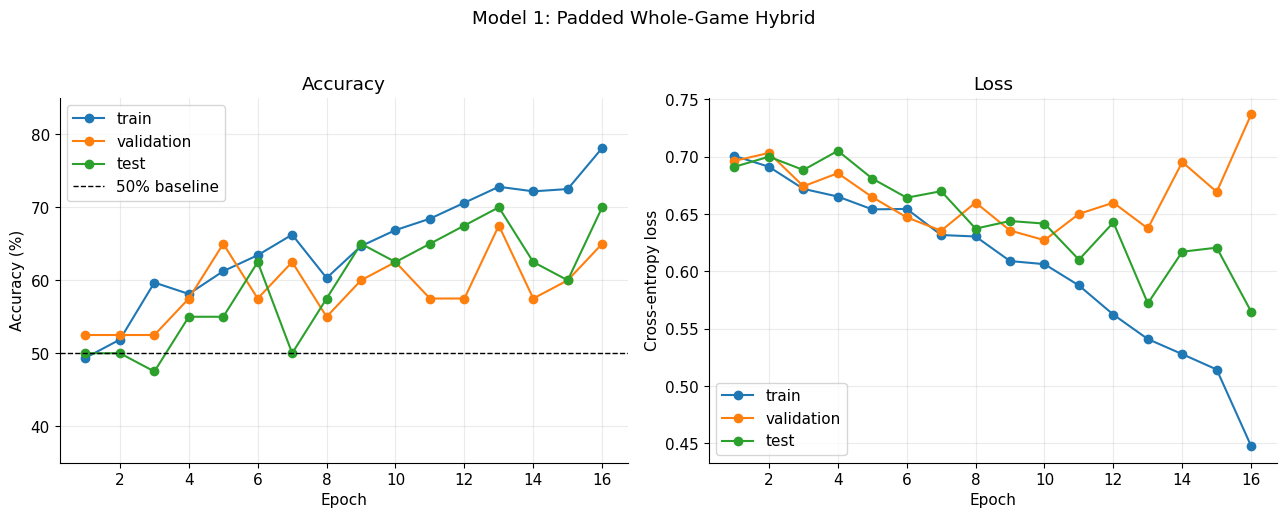

In [30]:
model1 = read_csv(model1_path)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Accuracy curves show whether the classifier is improving beyond the 50% binary baseline.
axes[0].plot(model1["epoch"], model1["train_acc"] * 100, marker="o", label="train")
axes[0].plot(model1["epoch"], model1["val_acc"] * 100, marker="o", label="validation")
axes[0].plot(model1["epoch"], model1["test_acc"] * 100, marker="o", label="test")
axes[0].axhline(50, color="black", linestyle="--", linewidth=1, label="50% baseline")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(35, 85)
axes[0].legend()

# Loss curves are useful for spotting overfitting: train loss can keep falling
# while validation/test loss flatten or rise.
axes[1].plot(model1["epoch"], model1["train_loss"], marker="o", label="train")
axes[1].plot(model1["epoch"], model1["val_loss"], marker="o", label="validation")
axes[1].plot(model1["epoch"], model1["test_loss"], marker="o", label="test")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")
axes[1].legend()

fig.suptitle("Model 1: Padded Whole-Game Hybrid", y=1.03)
fig.tight_layout()
fig.savefig(FIG / "final_model1_padded_hybrid_accuracy_loss.png", dpi=200, bbox_inches="tight")
plt.show()


## 6. Model 2: Controlled Style-Trajectory Classifier

Model 2 is the strongest final approach.

Pipeline:

```text
controlled continuation PGN
  -> select target-side moves
  -> Stockfish evaluates board before and after each played move
  -> aggregate 33 style_trajectory features
  -> train SVM / random forest classifiers
```

The main input vector is 33-dimensional, and the classifier output for a binary human-vs-Stockfish pair is 2 scores or probabilities.

The final feature set avoids direct Stockfish top-move agreement.

It does **not** use:

- top-1 Stockfish match
- top-3 Stockfish match
- Stockfish rank of the played move
- centipawn gap to Stockfish's best move

It does use board trajectory and move behavior:

- evaluation before/after moves
- evaluation volatility and trend
- large negative swing rates
- material balance and material changes
- legal move count
- capture/check/castle/promotion rates
- destination centrality
- attacked-destination rate
- pawn-advance rate
- piece-move mix

Unlike Model 1, Model 2 is a classical feature-based pipeline, so there is no single neural parameter count to report. For SVMs, the learned weights scale with the 33 input features; for Random Forests, model size is better described by the number of trees and tree depth rather than a single parameter total.

## 7. Run Model 2 For High-Count GMs

This cell discovers recognized GM folders in `data/raw`, counts usable games, removes labels that would make the splits too small, builds a separate same-FEN human-vs-Stockfish controlled dataset for each remaining GM, and then runs a binary classifier for each pair.

The controlled dataset size is now increased to 200 human continuations and 200 Stockfish continuations per included player. With the script's 80/10/10 split, each pair has about 160 training games, 20 validation games, and 20 test games per class.

Players with too few usable raw games are excluded. In the current data, Morphy is the limiting folder, so it is skipped for the main Model 2 comparison.


In [4]:
from src.dataset import LABELS, _open_pgn, _target_color_for_game, _count_target_moves
%pip install chess
import chess.pgn

raw_dir = ROOT / "data" / "raw"
controlled_pairs_root = ROOT / "data" / "controlled_pairs"
controlled_pairs_root.mkdir(parents=True, exist_ok=True)

CONTROLLED_GAMES_PER_LABEL = 200
MIN_USABLE_RAW_GAMES = 400
MODEL2_MAX_ANALYZED_MOVES = 30


def count_usable_raw_games(label):
    label_dir = raw_dir / label
    total = 0
    usable = 0
    for pgn_path in sorted(label_dir.glob("*.pgn")) + sorted(label_dir.glob("*.pgn.gz")):
        with _open_pgn(str(pgn_path)) as pgn_file:
            while True:
                game = chess.pgn.read_game(pgn_file)
                if game is None:
                    break
                total += 1
                target_color = _target_color_for_game(game, label)
                if target_color is not None and _count_target_moves(game, target_color) >= MODEL2_MAX_ANALYZED_MOVES:
                    usable += 1
    return total, usable


def count_games_in_pgn(path):
    path = Path(path)
    if not path.exists():
        return 0
    count = 0
    with _open_pgn(str(path)) as pgn_file:
        while chess.pgn.read_game(pgn_file) is not None:
            count += 1
    return count


raw_count_rows = []
for label_dir in sorted(p for p in raw_dir.iterdir() if p.is_dir()):
    label = label_dir.name
    if label not in LABELS or label == "stockfish":
        continue
    total, usable = count_usable_raw_games(label)
    raw_count_rows.append({"label": label, "raw_games": total, "usable_games": usable})

raw_counts = pd.DataFrame(raw_count_rows).sort_values("usable_games", ascending=False)
display(raw_counts)

human_labels = raw_counts.loc[raw_counts["usable_games"] >= MIN_USABLE_RAW_GAMES, "label"].sort_values().tolist()
skipped_labels = raw_counts.loc[raw_counts["usable_games"] < MIN_USABLE_RAW_GAMES, "label"].sort_values().tolist()
print("Included labels:", human_labels)
print("Skipped labels due to small usable raw count:", skipped_labels)

pair_paths = {}
for label in human_labels:
    pair_dir = controlled_pairs_root / f"{label}_stockfish_g{CONTROLLED_GAMES_PER_LABEL}"
    human_pgn = pair_dir / label / f"{label}_controlled.pgn"
    stockfish_pgn = pair_dir / "stockfish" / "controlled_stockfish.pgn"
    existing_human = count_games_in_pgn(human_pgn)
    existing_stockfish = count_games_in_pgn(stockfish_pgn)

    needs_pair_data = (
        FORCE_RERUN
        or existing_human < CONTROLLED_GAMES_PER_LABEL
        or existing_stockfish < CONTROLLED_GAMES_PER_LABEL
    )
    if needs_pair_data:
        run_command([
            "python3", "scripts/make_controlled_engine_dataset.py",
            "--source-dir", "data/raw",
            "--out-dir", str(pair_dir),
            "--labels", label,
            "--games-per-label", str(CONTROLLED_GAMES_PER_LABEL),
            "--target-moves-before-fen", "10",
            "--continuation-plies", "50",
        ], force=True)
    else:
        print(
            f"Using existing controlled pair data for {label}: "
            f"{existing_human} human / {existing_stockfish} stockfish games"
        )

    out_path = OUT / f"controlled_pair_{label}_stockfish_style_trajectory_d4_m30_g{CONTROLLED_GAMES_PER_LABEL}.csv"
    pair_paths[label] = out_path
    run_command([
        "python3", "retrieval/run_engine_quality_baseline.py",
        "--data-dir", str(pair_dir),
        "--include-label", label,
        "--include-label", "stockfish",
        "--max-games-per-label", str(CONTROLLED_GAMES_PER_LABEL),
        "--stockfish-pairs-only",
        "--stockfish-side", "alternate",
        "--skip-moves", "0",
        "--max-analyzed-moves", str(MODEL2_MAX_ANALYZED_MOVES),
        "--engine-depth", "4",
        "--feature-set", "style_trajectory",
        "--classification-mode", "pairwise",
        "--results-path", str(out_path),
    ], output_path=out_path, force=FORCE_RERUN)


Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


,label,raw_games,usable_games
3,carlsen,7484,6448
0,anand,4211,3154
5,karpov,3529,2662
9,tal,2431,1527
6,kasparov,2128,1521
8,petrosian,1893,1113
1,botvinnik,891,697
4,fischer,827,647
2,capablanca,597,437
7,morphy,211,107


Note: you may need to restart the kernel to use updated packages.


,label,raw_games,usable_games
3,carlsen,7484,6448
0,anand,4211,3154
5,karpov,3529,2662
9,tal,2431,1527
6,kasparov,2128,1521
8,petrosian,1893,1113
1,botvinnik,891,697
4,fischer,827,647
2,capablanca,597,437
7,morphy,211,107


Included labels: ['anand', 'botvinnik', 'capablanca', 'carlsen', 'fischer', 'karpov', 'kasparov', 'petrosian', 'tal']
Skipped labels due to small usable raw count: ['morphy']
Using existing controlled pair data for anand: 200 human / 200 stockfish games
Using existing /Users/aadil/Chess-ML-Project/chess-style-fingerprint/outputs/controlled_pair_anand_stockfish_style_trajectory_d4_m30_g200.csv
Using existing controlled pair data for botvinnik: 200 human / 200 stockfish games
Using existing /Users/aadil/Chess-ML-Project/chess-style-fingerprint/outputs/controlled_pair_botvinnik_stockfish_style_trajectory_d4_m30_g200.csv
Using existing controlled pair data for capablanca: 200 human / 200 stockfish games
Using existing /Users/aadil/Chess-ML-Project/chess-style-fingerprint/outputs/controlled_pair_capablanca_stockfish_style_trajectory_d4_m30_g200.csv
Using existing controlled pair data for carlsen: 200 human / 200 stockfish games
Using existing /Users/aadil/Chess-ML-Project/chess-style-finger

In [5]:
summary_rows = []
for label, path in pair_paths.items():
    df = read_csv(path)
    table = classifier_table(df)
    row = df.iloc[0]
    for _, model_row in table.iterrows():
        summary_rows.append({
            "human_label": label,
            "classes": row.get("classes", f"{label},stockfish"),
            "feature_set": row.get("feature_set", "style_trajectory"),
            "majority_baseline": float(row.get("majority_baseline", 0.5)),
            "model_key": model_row["model_key"],
            "model": model_row["model"],
            "train_acc": model_row["train_acc"],
            "val_acc": model_row["val_acc"],
            "test_acc": model_row["test_acc"],
            "test_loss": model_row["test_loss"],
        })

all_pairs = pd.DataFrame(summary_rows)
summary_path = OUT / f"model2_all_human_vs_stockfish_style_trajectory_summary_g{CONTROLLED_GAMES_PER_LABEL}.csv"
all_pairs.to_csv(summary_path, index=False)
print(f"Saved {summary_path}")
all_pairs.sort_values(["human_label", "test_acc"], ascending=[True, False])


Saved /Users/aadil/Chess-ML-Project/chess-style-fingerprint/outputs/model2_all_human_vs_stockfish_style_trajectory_summary_g200.csv


,human_label,classes,feature_set,majority_baseline,model_key,model,train_acc,val_acc,test_acc,test_loss
0,anand,"anand,stockfish",style_trajectory,0.5,svm_rbf,RBF SVM,0.787500,0.525,0.675,0.660170
1,anand,"anand,stockfish",style_trajectory,0.5,gbdt,Gradient Boosting,0.993750,0.450,0.650,0.639274
2,anand,"anand,stockfish",style_trajectory,0.5,logreg,Logistic,0.715625,0.375,0.600,0.680008
3,anand,"anand,stockfish",style_trajectory,0.5,svm_linear,Linear SVM,0.712500,0.350,0.600,0.636343
4,anand,"anand,stockfish",style_trajectory,0.5,forest,Random Forest,0.821875,0.450,0.575,0.663865
...,...,...,...,...,...,...,...,...,...,...
58,tal,"tal,stockfish",style_trajectory,0.5,forest,Random Forest,0.834375,0.750,0.775,0.489914
59,tal,"tal,stockfish",style_trajectory,0.5,svm_linear,Linear SVM,0.709375,0.525,0.700,0.581381
60,tal,"tal,stockfish",style_trajectory,0.5,svm_rbf,RBF SVM,0.784375,0.600,0.675,0.626657
61,tal,"tal,stockfish",style_trajectory,0.5,mlp,MLP,1.000000,0.525,0.650,1.793671


## 8. Run Model 1 For All High-Count GM-vs-Stockfish Pairs

This section trains the same Model 1 neural architecture for every high-count GM-vs-Stockfish controlled pair. It reuses the pair-specific controlled datasets created in the previous cell, so each Stockfish class is generated from that same player's midgame FENs.

This is expensive: it trains one neural network per included player. The settings match the main Model 1 run: small model, 200 games per class, 80-move padded sequence, 8 epochs.


In [7]:
RUN_MODEL1_ALL_PAIRS = True

MODEL1_PAIR_SCALE = "small"
MODEL1_PAIR_EPOCHS = 16
MODEL1_PAIR_LR = "1e-4"
MODEL1_PAIR_BATCH_SIZE = 16
MODEL1_PAIR_ENGINE_DEPTH = 2
MODEL1_PAIR_MAX_ANALYZED_MOVES = 30

model1_pair_paths = {}
if RUN_MODEL1_ALL_PAIRS:
    for label in human_labels:
        pair_dir = controlled_pairs_root / f"{label}_stockfish_g{CONTROLLED_GAMES_PER_LABEL}"
        out_path = OUT / (
            f"model1_pair_{label}_stockfish_"
            f"{MODEL1_PAIR_SCALE}_d{MODEL1_PAIR_ENGINE_DEPTH}_"
            f"m{MODEL1_PAIR_MAX_ANALYZED_MOVES}_g{CONTROLLED_GAMES_PER_LABEL}_"
            f"e{MODEL1_PAIR_EPOCHS}_b{MODEL1_PAIR_BATCH_SIZE}_lr1e4.csv"
        )
        model1_pair_paths[label] = out_path
        run_command([
            "python3", "scripts/run_hybrid_experiment.py",
            "--data-dir", str(pair_dir),
            "--include-label", label,
            "--include-label", "stockfish",
            "--max-games-per-label", str(CONTROLLED_GAMES_PER_LABEL),
            "--stockfish-side", "alternate",
            "--sequence-mode", "padded",
            "--window-length", "80",
            "--skip-moves", "0",
            "--max-analyzed-moves", str(MODEL1_PAIR_MAX_ANALYZED_MOVES),
            "--engine-depth", str(MODEL1_PAIR_ENGINE_DEPTH),
            "--feature-set", "style_trajectory",
            "--epochs", str(MODEL1_PAIR_EPOCHS),
            "--batch-size", str(MODEL1_PAIR_BATCH_SIZE),
            "--model-scale", MODEL1_PAIR_SCALE,
            "--lr", MODEL1_PAIR_LR,
            "--results-path", str(out_path),
        ], output_path=out_path, force=FORCE_RERUN)
else:
    print("Model 1 all-pairs run skipped. Set RUN_MODEL1_ALL_PAIRS = True to run it.")


Running: python3 scripts/run_hybrid_experiment.py --data-dir /Users/aadil/Chess-ML-Project/chess-style-fingerprint/data/controlled_pairs/anand_stockfish_g200 --include-label anand --include-label stockfish --max-games-per-label 200 --stockfish-side alternate --sequence-mode padded --window-length 80 --skip-moves 0 --max-analyzed-moves 30 --engine-depth 2 --feature-set style_trajectory --epochs 16 --batch-size 16 --model-scale small --lr 1e-4 --results-path /Users/aadil/Chess-ML-Project/chess-style-fingerprint/outputs/model1_pair_anand_stockfish_small_d2_m30_g200_e16_b16_lr1e4.csv

Labels with no usable games:
  botvinnik
  capablanca
  carlsen
  fischer
  karpov
  kasparov
  morphy
  petrosian
  tal
Using 200 games for anand
Using 200 games for stockfish
Game counts:
  train: {'anand': 160, 'stockfish': 160}
  val: {'anand': 20, 'stockfish': 20}
  test: {'anand': 20, 'stockfish': 20}
Materializing train samples...
  materialized 25/320 games
  materialized 50/320 games
  materialized 7

/Users/aadil/Chess-ML-Project/chess-style-fingerprint/src/model.py:202: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)


Epoch 01/16 | train_loss=0.7038 train_acc=48.1% | val_acc=52.5% | test_acc=62.5%
Epoch 02/16 | train_loss=0.6973 train_acc=51.2% | val_acc=52.5% | test_acc=47.5%
Epoch 03/16 | train_loss=0.6858 train_acc=56.2% | val_acc=40.0% | test_acc=62.5%
Epoch 04/16 | train_loss=0.6868 train_acc=52.5% | val_acc=47.5% | test_acc=55.0%
Epoch 05/16 | train_loss=0.6798 train_acc=55.9% | val_acc=52.5% | test_acc=52.5%
Epoch 06/16 | train_loss=0.6892 train_acc=52.8% | val_acc=37.5% | test_acc=55.0%
Epoch 07/16 | train_loss=0.6662 train_acc=60.3% | val_acc=40.0% | test_acc=57.5%
Epoch 08/16 | train_loss=0.6725 train_acc=59.1% | val_acc=32.5% | test_acc=55.0%
Epoch 09/16 | train_loss=0.6679 train_acc=62.2% | val_acc=47.5% | test_acc=52.5%
Epoch 10/16 | train_loss=0.6709 train_acc=58.1% | val_acc=40.0% | test_acc=60.0%
Epoch 11/16 | train_loss=0.6549 train_acc=61.6% | val_acc=32.5% | test_acc=52.5%
Epoch 12/16 | train_loss=0.6479 train_acc=62.2% | val_acc=45.0% | test_acc=62.5%
Epoch 13/16 | train_loss=0.6

/Users/aadil/Chess-ML-Project/chess-style-fingerprint/src/model.py:202: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)


Epoch 01/16 | train_loss=0.7074 train_acc=45.6% | val_acc=50.0% | test_acc=50.0%
Epoch 02/16 | train_loss=0.7004 train_acc=47.2% | val_acc=52.5% | test_acc=50.0%
Epoch 03/16 | train_loss=0.6879 train_acc=54.7% | val_acc=60.0% | test_acc=52.5%
Epoch 04/16 | train_loss=0.6879 train_acc=50.0% | val_acc=52.5% | test_acc=52.5%
Epoch 05/16 | train_loss=0.6773 train_acc=56.2% | val_acc=50.0% | test_acc=50.0%
Epoch 06/16 | train_loss=0.6901 train_acc=51.6% | val_acc=57.5% | test_acc=47.5%
Epoch 07/16 | train_loss=0.6648 train_acc=61.3% | val_acc=70.0% | test_acc=50.0%
Epoch 08/16 | train_loss=0.6712 train_acc=60.0% | val_acc=67.5% | test_acc=45.0%
Epoch 09/16 | train_loss=0.6627 train_acc=60.9% | val_acc=55.0% | test_acc=52.5%
Epoch 10/16 | train_loss=0.6639 train_acc=57.2% | val_acc=62.5% | test_acc=55.0%
Epoch 11/16 | train_loss=0.6502 train_acc=58.1% | val_acc=62.5% | test_acc=52.5%
Epoch 12/16 | train_loss=0.6381 train_acc=65.6% | val_acc=67.5% | test_acc=52.5%
Epoch 13/16 | train_loss=0.6

...

Epoch 01/16 | train_loss=0.7028 train_acc=50.9% | val_acc=50.0% | test_acc=47.5%
Epoch 02/16 | train_loss=0.6924 train_acc=51.6% | val_acc=45.0% | test_acc=60.0%
Epoch 03/16 | train_loss=0.6803 train_acc=56.9% | val_acc=55.0% | test_acc=50.0%
Epoch 04/16 | train_loss=0.6743 train_acc=60.3% | val_acc=55.0% | test_acc=50.0%
Epoch 05/16 | train_loss=0.6558 train_acc=63.4% | val_acc=52.5% | test_acc=50.0%
Epoch 06/16 | train_loss=0.6643 train_acc=61.3% | val_acc=47.5% | test_acc=57.5%
Epoch 07/16 | train_loss=0.6430 train_acc=64.4% | val_acc=55.0% | test_acc=57.5%
Epoch 08/16 | train_loss=0.6382 train_acc=62.8% | val_acc=52.5% | test_acc=52.5%
Epoch 09/16 | train_loss=0.6195 train_acc=66.9% | val_acc=50.0% | test_acc=60.0%
Epoch 10/16 | train_loss=0.5953 train_acc=71.2% | val_acc=55.0% | test_acc=62.5%
Epoch 11/16 | train_loss=0.5745 train_acc=70.0% | val_acc=57.5% | test_acc=55.0%
Epoch 12/16 | train_loss=0.5578 train_acc=73.8% | val_acc=50.0% | test_acc=57.5%
Epoch 13/16 | train_loss=0.5

/Users/aadil/Chess-ML-Project/chess-style-fingerprint/src/model.py:202: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)


Epoch 01/16 | train_loss=0.7061 train_acc=46.6% | val_acc=50.0% | test_acc=50.0%
Epoch 02/16 | train_loss=0.6981 train_acc=50.0% | val_acc=60.0% | test_acc=57.5%
Epoch 03/16 | train_loss=0.6854 train_acc=53.4% | val_acc=45.0% | test_acc=55.0%
Epoch 04/16 | train_loss=0.6864 train_acc=52.5% | val_acc=50.0% | test_acc=52.5%
Epoch 05/16 | train_loss=0.6767 train_acc=55.6% | val_acc=47.5% | test_acc=52.5%
Epoch 06/16 | train_loss=0.6833 train_acc=53.4% | val_acc=52.5% | test_acc=57.5%
Epoch 07/16 | train_loss=0.6620 train_acc=63.7% | val_acc=62.5% | test_acc=62.5%
Epoch 08/16 | train_loss=0.6664 train_acc=60.0% | val_acc=45.0% | test_acc=55.0%
Epoch 09/16 | train_loss=0.6577 train_acc=61.3% | val_acc=52.5% | test_acc=50.0%
Epoch 10/16 | train_loss=0.6622 train_acc=58.1% | val_acc=67.5% | test_acc=60.0%
Epoch 11/16 | train_loss=0.6418 train_acc=61.9% | val_acc=50.0% | test_acc=57.5%
Epoch 12/16 | train_loss=0.6348 train_acc=64.4% | val_acc=65.0% | test_acc=57.5%
Epoch 13/16 | train_loss=0.6

/Users/aadil/Chess-ML-Project/chess-style-fingerprint/src/model.py:202: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)


Epoch 01/16 | train_loss=0.7029 train_acc=48.1% | val_acc=50.0% | test_acc=50.0%
Epoch 02/16 | train_loss=0.6908 train_acc=51.9% | val_acc=50.0% | test_acc=50.0%
Epoch 03/16 | train_loss=0.6726 train_acc=60.6% | val_acc=57.5% | test_acc=57.5%
Epoch 04/16 | train_loss=0.6692 train_acc=60.9% | val_acc=55.0% | test_acc=52.5%
Epoch 05/16 | train_loss=0.6563 train_acc=58.8% | val_acc=52.5% | test_acc=57.5%
Epoch 06/16 | train_loss=0.6498 train_acc=62.2% | val_acc=55.0% | test_acc=60.0%
Epoch 07/16 | train_loss=0.6256 train_acc=64.7% | val_acc=57.5% | test_acc=67.5%
Epoch 08/16 | train_loss=0.6271 train_acc=66.9% | val_acc=67.5% | test_acc=62.5%
Epoch 09/16 | train_loss=0.6027 train_acc=65.9% | val_acc=52.5% | test_acc=67.5%
Epoch 10/16 | train_loss=0.5970 train_acc=67.5% | val_acc=50.0% | test_acc=75.0%
Epoch 11/16 | train_loss=0.5891 train_acc=66.2% | val_acc=67.5% | test_acc=65.0%
Epoch 12/16 | train_loss=0.5729 train_acc=72.8% | val_acc=55.0% | test_acc=75.0%
Epoch 13/16 | train_loss=0.5

## 9. Model 1 All-Pairs Summary

For the neural model, use validation accuracy as the fair checkpoint-selection metric. The table reports the test accuracy at the best-validation epoch, plus the best test epoch for context.


In [8]:
def ensure_model1_pair_paths():
    """Create model1_pair_paths from expected outputs or existing pair CSVs."""
    global model1_pair_paths, human_labels
    global MODEL1_PAIR_SCALE, MODEL1_PAIR_EPOCHS, MODEL1_PAIR_LR, MODEL1_PAIR_BATCH_SIZE
    global MODEL1_PAIR_ENGINE_DEPTH, MODEL1_PAIR_MAX_ANALYZED_MOVES, CONTROLLED_GAMES_PER_LABEL

    if "MODEL1_PAIR_SCALE" not in globals():
        MODEL1_PAIR_SCALE = "small"
    if "MODEL1_PAIR_EPOCHS" not in globals():
        MODEL1_PAIR_EPOCHS = 16
    if "MODEL1_PAIR_LR" not in globals():
        MODEL1_PAIR_LR = "1e-4"
    if "MODEL1_PAIR_BATCH_SIZE" not in globals():
        MODEL1_PAIR_BATCH_SIZE = 16
    if "MODEL1_PAIR_ENGINE_DEPTH" not in globals():
        MODEL1_PAIR_ENGINE_DEPTH = 2
    if "MODEL1_PAIR_MAX_ANALYZED_MOVES" not in globals():
        MODEL1_PAIR_MAX_ANALYZED_MOVES = 30
    if "CONTROLLED_GAMES_PER_LABEL" not in globals():
        CONTROLLED_GAMES_PER_LABEL = 200

    if "model1_pair_paths" in globals() and model1_pair_paths:
        return model1_pair_paths

    model1_pair_paths = {}
    if "human_labels" in globals() and human_labels:
        for label in human_labels:
            model1_pair_paths[label] = OUT / (
                f"model1_pair_{label}_stockfish_"
                f"{MODEL1_PAIR_SCALE}_d{MODEL1_PAIR_ENGINE_DEPTH}_"
                f"m{MODEL1_PAIR_MAX_ANALYZED_MOVES}_g{CONTROLLED_GAMES_PER_LABEL}_"
                f"e{MODEL1_PAIR_EPOCHS}_b{MODEL1_PAIR_BATCH_SIZE}_lr1e4.csv"
            )
        return model1_pair_paths

    files = sorted(OUT.glob(
        f"model1_pair_*_stockfish_{MODEL1_PAIR_SCALE}_d{MODEL1_PAIR_ENGINE_DEPTH}_"
        f"m{MODEL1_PAIR_MAX_ANALYZED_MOVES}_g{CONTROLLED_GAMES_PER_LABEL}_"
        f"e{MODEL1_PAIR_EPOCHS}_b{MODEL1_PAIR_BATCH_SIZE}_lr1e4.csv"
    ))
    if not files:
        raise RuntimeError(
            "model1_pair_paths is not defined and no Model 1 pair CSVs were found. "
            "Run the Model 1 all-pairs training cell first."
        )
    for path in files:
        label = path.name.replace("model1_pair_", "").replace(
            f"_stockfish_{MODEL1_PAIR_SCALE}_d{MODEL1_PAIR_ENGINE_DEPTH}_"
            f"m{MODEL1_PAIR_MAX_ANALYZED_MOVES}_g{CONTROLLED_GAMES_PER_LABEL}_"
            f"e{MODEL1_PAIR_EPOCHS}_b{MODEL1_PAIR_BATCH_SIZE}_lr1e4.csv",
            "",
        )
        model1_pair_paths[label] = path
    human_labels = sorted(model1_pair_paths)
    print("Reconstructed model1_pair_paths from existing CSVs:", human_labels)
    return model1_pair_paths

ensure_model1_pair_paths()

model1_pair_rows = []
for label, path in model1_pair_paths.items():
    if not Path(path).exists():
        continue
    df = read_csv(path)
    best_val = df.loc[df["val_acc"].idxmax()]
    best_test = df.loc[df["test_acc"].idxmax()]
    final = df.iloc[-1]
    model1_pair_rows.append({
        "human_label": label,
        "scale": MODEL1_PAIR_SCALE,
        "epochs": MODEL1_PAIR_EPOCHS,
        "batch_size": MODEL1_PAIR_BATCH_SIZE,
        "learning_rate": MODEL1_PAIR_LR,
        "engine_depth": MODEL1_PAIR_ENGINE_DEPTH,
        "games_per_class": CONTROLLED_GAMES_PER_LABEL,
        "expected_train_per_class": int(0.8 * CONTROLLED_GAMES_PER_LABEL),
        "expected_val_per_class": int(0.1 * CONTROLLED_GAMES_PER_LABEL),
        "expected_test_per_class": CONTROLLED_GAMES_PER_LABEL - int(0.8 * CONTROLLED_GAMES_PER_LABEL) - int(0.1 * CONTROLLED_GAMES_PER_LABEL),
        "best_val_epoch": int(best_val["epoch"]),
        "best_val_acc": float(best_val["val_acc"]),
        "test_at_best_val": float(best_val["test_acc"]),
        "best_test_epoch": int(best_test["epoch"]),
        "best_test_acc": float(best_test["test_acc"]),
        "final_val_acc": float(final["val_acc"]),
        "final_test_acc": float(final["test_acc"]),
        "source": Path(path).name,
    })

model1_all_pairs = pd.DataFrame(model1_pair_rows)
if not model1_all_pairs.empty:
    model1_all_pairs = model1_all_pairs.sort_values("test_at_best_val", ascending=False)
model1_all_pairs_path = OUT / f"model1_all_pairs_summary_g{CONTROLLED_GAMES_PER_LABEL}_e{MODEL1_PAIR_EPOCHS}_b{MODEL1_PAIR_BATCH_SIZE}_lr1e4.csv"
model1_all_pairs.to_csv(model1_all_pairs_path, index=False)
print(f"Saved {model1_all_pairs_path}")
model1_all_pairs


Saved /Users/aadil/Chess-ML-Project/chess-style-fingerprint/outputs/model1_all_pairs_summary_g200_e16_b16_lr1e4.csv


,human_label,scale,epochs,batch_size,learning_rate,engine_depth,games_per_class,expected_train_per_class,expected_val_per_class,expected_test_per_class,best_val_epoch,best_val_acc,test_at_best_val,best_test_epoch,best_test_acc,final_val_acc,final_test_acc,source
4,fischer,small,16,16,1e-4,2,200,160,20,20,11,0.850,0.675,9,0.700,0.750,0.675,model1_pair_fischer_stockfish_small_d2_m30_g20...
0,anand,small,16,16,1e-4,2,200,160,20,20,1,0.525,0.625,15,0.650,0.475,0.625,model1_pair_anand_stockfish_small_d2_m30_g200_...
2,capablanca,small,16,16,1e-4,2,200,160,20,20,2,0.600,0.625,16,0.725,0.550,0.725,model1_pair_capablanca_stockfish_small_d2_m30_...
8,tal,small,16,16,1e-4,2,200,160,20,20,8,0.675,0.625,15,0.800,0.600,0.625,model1_pair_tal_stockfish_small_d2_m30_g200_e1...
7,petrosian,small,16,16,1e-4,2,200,160,20,20,10,0.675,0.600,7,0.625,0.650,0.625,model1_pair_petrosian_stockfish_small_d2_m30_g...
6,kasparov,small,16,16,1e-4,2,200,160,20,20,11,0.575,0.550,14,0.650,0.575,0.525,model1_pair_kasparov_stockfish_small_d2_m30_g2...
5,karpov,small,16,16,1e-4,2,200,160,20,20,7,0.625,0.525,10,0.650,0.450,0.650,model1_pair_karpov_stockfish_small_d2_m30_g200...
1,botvinnik,small,16,16,1e-4,2,200,160,20,20,7,0.700,0.500,16,0.675,0.550,0.675,model1_pair_botvinnik_stockfish_small_d2_m30_g...
3,carlsen,small,16,16,1e-4,2,200,160,20,20,12,0.550,0.500,7,0.625,0.525,0.450,model1_pair_carlsen_stockfish_small_d2_m30_g20...


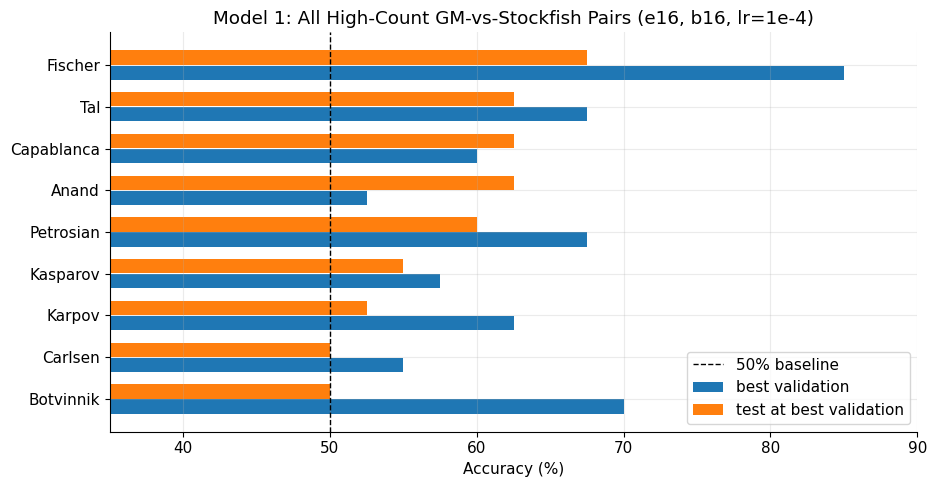

In [9]:
if not model1_all_pairs.empty:
    plot_df = model1_all_pairs.sort_values("test_at_best_val")
    fig, ax = plt.subplots(figsize=(9.5, 5))
    y = np.arange(len(plot_df))
    ax.barh(y - 0.18, plot_df["best_val_acc"] * 100, height=0.34, label="best validation")
    ax.barh(y + 0.18, plot_df["test_at_best_val"] * 100, height=0.34, label="test at best validation")
    ax.axvline(50, color="black", linestyle="--", linewidth=1, label="50% baseline")
    ax.set_yticks(y)
    ax.set_yticklabels([name.capitalize() for name in plot_df["human_label"]])
    ax.set_xlabel("Accuracy (%)")
    ax.set_title("Model 1: All High-Count GM-vs-Stockfish Pairs (e16, b16, lr=1e-4)")
    ax.set_xlim(35, 90)
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIG / "final_model1_all_pairs_accuracy_g200_e16_b16_lr1e4.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("No Model 1 all-pairs results available yet.")


In [10]:
summary_rows = []
for label, path in pair_paths.items():
    df = read_csv(path)
    table = classifier_table(df)
    row = df.iloc[0]
    for _, model_row in table.iterrows():
        summary_rows.append({
            "human_label": label,
            "classes": row.get("classes", f"{label},stockfish"),
            "feature_set": row.get("feature_set", "style_trajectory"),
            "majority_baseline": float(row.get("majority_baseline", 0.5)),
            "model_key": model_row["model_key"],
            "model": model_row["model"],
            "train_acc": model_row["train_acc"],
            "val_acc": model_row["val_acc"],
            "test_acc": model_row["test_acc"],
            "test_loss": model_row["test_loss"],
        })

all_pairs = pd.DataFrame(summary_rows)
summary_path = OUT / f"model2_all_human_vs_stockfish_style_trajectory_summary_g{CONTROLLED_GAMES_PER_LABEL}.csv"
all_pairs.to_csv(summary_path, index=False)
print(f"Saved {summary_path}")
all_pairs.sort_values(["human_label", "test_acc"], ascending=[True, False])


Saved /Users/aadil/Chess-ML-Project/chess-style-fingerprint/outputs/model2_all_human_vs_stockfish_style_trajectory_summary_g200.csv


,human_label,classes,feature_set,majority_baseline,model_key,model,train_acc,val_acc,test_acc,test_loss
0,anand,"anand,stockfish",style_trajectory,0.5,svm_rbf,RBF SVM,0.787500,0.525,0.675,0.660170
1,anand,"anand,stockfish",style_trajectory,0.5,gbdt,Gradient Boosting,0.993750,0.450,0.650,0.639274
2,anand,"anand,stockfish",style_trajectory,0.5,logreg,Logistic,0.715625,0.375,0.600,0.680008
3,anand,"anand,stockfish",style_trajectory,0.5,svm_linear,Linear SVM,0.712500,0.350,0.600,0.636343
4,anand,"anand,stockfish",style_trajectory,0.5,forest,Random Forest,0.821875,0.450,0.575,0.663865
...,...,...,...,...,...,...,...,...,...,...
58,tal,"tal,stockfish",style_trajectory,0.5,forest,Random Forest,0.834375,0.750,0.775,0.489914
59,tal,"tal,stockfish",style_trajectory,0.5,svm_linear,Linear SVM,0.709375,0.525,0.700,0.581381
60,tal,"tal,stockfish",style_trajectory,0.5,svm_rbf,RBF SVM,0.784375,0.600,0.675,0.626657
61,tal,"tal,stockfish",style_trajectory,0.5,mlp,MLP,1.000000,0.525,0.650,1.793671


## 10. Model 2 Results: SVM And Random Forest


- **Linear SVM**: course-standard linear separating boundary.
- **RBF SVM**: nonlinear SVM boundary.
- **Random Forest**: tree ensemble that learns threshold rules over interpretable style features.

Other models are diagnostic baselines 

In [11]:
report_df = all_pairs[all_pairs["model_key"].isin(REPORT_MODELS)].copy()
report_pivot = report_df.pivot_table(
    index="human_label",
    columns="model",
    values="test_acc",
    aggfunc="max",
).sort_index()
report_pivot_pct = (report_pivot * 100).round(1)
report_pivot_pct

model,Linear SVM,RBF SVM,Random Forest
human_label,,,
anand,60.0,67.5,57.5
botvinnik,45.0,30.0,60.0
capablanca,60.0,62.5,67.5
carlsen,47.5,57.5,77.5
fischer,60.0,57.5,72.5
karpov,70.0,67.5,70.0
kasparov,55.0,57.5,62.5
petrosian,67.5,70.0,70.0
tal,70.0,67.5,77.5


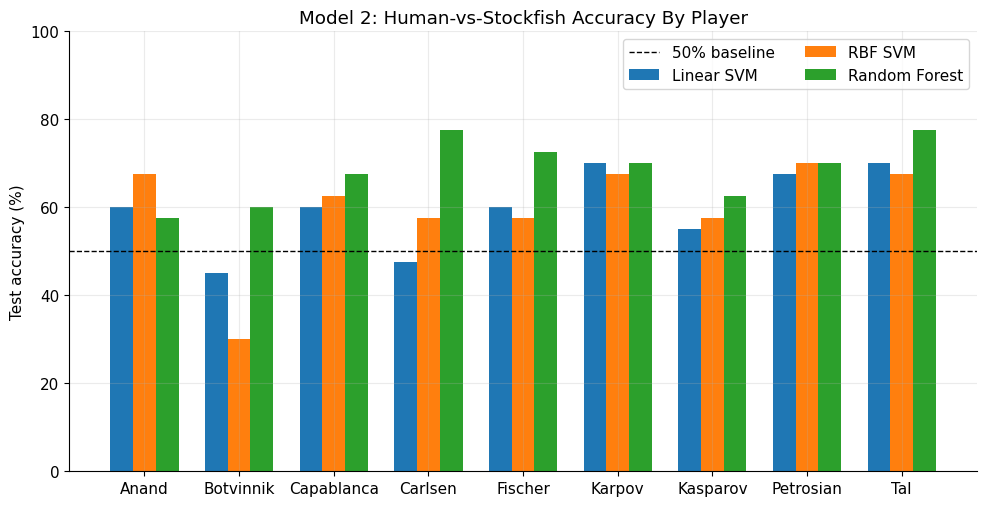

In [12]:
plot_df = report_pivot.sort_index()
fig, ax = plt.subplots(figsize=(10, 5.2))
x = np.arange(len(plot_df.index))
width = 0.24
for i, model_name in enumerate(["Linear SVM", "RBF SVM", "Random Forest"]):
    if model_name in plot_df.columns:
        ax.bar(x + (i - 1) * width, plot_df[model_name] * 100, width=width, label=model_name)
ax.axhline(50, color="black", linestyle="--", linewidth=1, label="50% baseline")
ax.set_xticks(x)
ax.set_xticklabels([name.capitalize() for name in plot_df.index])
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Model 2: Human-vs-Stockfish Accuracy By Player")
ax.set_ylim(0, 100)
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(FIG / "final_model2_all_pairs_accuracy.png", dpi=200)
plt.show()

In [13]:
best_per_pair = all_pairs.loc[all_pairs.groupby("human_label")["test_acc"].idxmax()].copy()
best_per_pair = best_per_pair.sort_values("test_acc", ascending=False)
best_per_pair[["human_label", "model", "train_acc", "val_acc", "test_acc", "test_loss"]]

,human_label,model,train_acc,val_acc,test_acc,test_loss
56,tal,Gradient Boosting,1.000000,0.750,0.800,0.487796
21,carlsen,Random Forest,0.809375,0.775,0.775,0.563472
28,fischer,Random Forest,0.850000,0.725,0.725,0.539222
35,karpov,Logistic,0.743750,0.525,0.700,0.637476
49,petrosian,RBF SVM,0.834375,0.600,0.700,0.596233
0,anand,RBF SVM,0.787500,0.525,0.675,0.660170
14,capablanca,Random Forest,0.840625,0.600,0.675,0.597466
42,kasparov,Gradient Boosting,1.000000,0.600,0.650,0.786240
7,botvinnik,Random Forest,0.856250,0.775,0.600,0.611597


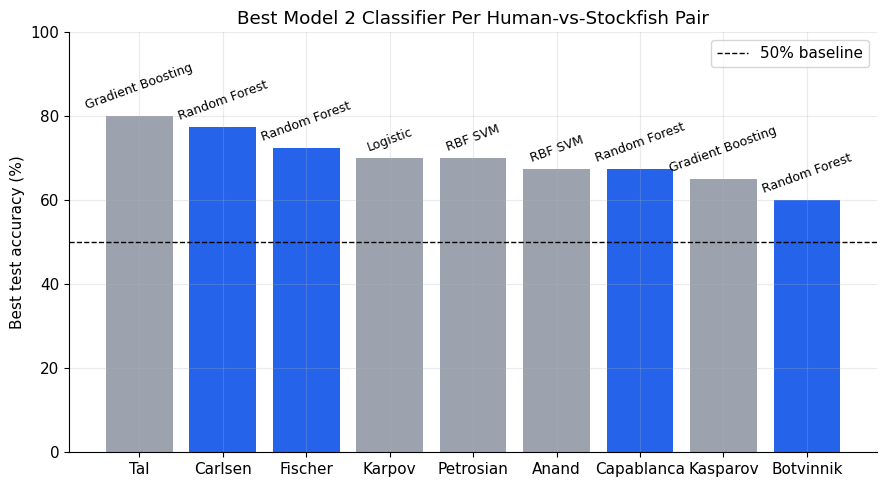

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
bar_labels = [name.capitalize() for name in best_per_pair["human_label"]]
colors = ["#2563eb" if m == "Random Forest" else "#9ca3af" for m in best_per_pair["model"]]
ax.bar(bar_labels, best_per_pair["test_acc"] * 100, color=colors)
ax.axhline(50, color="black", linestyle="--", linewidth=1, label="50% baseline")
ax.set_ylabel("Best test accuracy (%)")
ax.set_title("Best Model 2 Classifier Per Human-vs-Stockfish Pair")
ax.set_ylim(0, 100)
for i, (_, row) in enumerate(best_per_pair.iterrows()):
    ax.text(i, row["test_acc"] * 100 + 1, row["model"], ha="center", va="bottom", fontsize=9, rotation=20)
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "final_model2_best_per_pair.png", dpi=200)
plt.show()

## 11. Final Two-Model Comparison

This table compares the two final project models.

The key result is that the neural model is architecturally motivated and learns some signal, but the interpretable controlled style-trajectory classifier is stronger and easier to explain.

In [21]:
# This cell compares Model 1 and Model 2 using all-pairs averages when available.
# Model 1 uses best observed test accuracy from each pair summary, as requested.
model1_all_pairs_path = OUT / "model1_all_pairs_summary_g200_e16_b16_lr1e4.csv"
if not model1_all_pairs_path.exists():
    model1_all_pairs_path = OUT / "model1_all_pairs_summary_g200.csv"

if model1_all_pairs_path.exists():
    model1_all_pairs_for_comparison = read_csv(model1_all_pairs_path)
    model1_reported_test = float(model1_all_pairs_for_comparison["best_test_acc"].mean())
    model1_validation = float(model1_all_pairs_for_comparison["best_val_acc"].mean())
    model1_metric = "mean across all GM-vs-Stockfish pairs, using best observed test epoch"
    model1_source = f"{model1_all_pairs_path.name}; averaged over {len(model1_all_pairs_for_comparison)} pairs"
else:
    if "model1_path" not in globals():
        model1_path = OUT / "hybrid_padded80_tal_stockfish_style_small_d2_m30_g200_e8.csv"
    model1_results = read_csv(model1_path)
    model1_best = model1_results.loc[model1_results["test_acc"].idxmax()]
    model1_reported_test = float(model1_best["test_acc"])
    model1_validation = float(model1_best["val_acc"])
    model1_metric = "single Tal-vs-Stockfish run, best observed test epoch"
    model1_source = model1_path.name

if "summary_path" not in globals():
    summary_path = OUT / f"model2_all_human_vs_stockfish_style_trajectory_summary_g{CONTROLLED_GAMES_PER_LABEL}.csv"
model2_all_pairs = read_csv(summary_path)

# Main Model 2 result: choose one classifier by best average test accuracy across pairs.
classifier_average = (
    model2_all_pairs.groupby("model")
    .agg(
        mean_train_acc=("train_acc", "mean"),
        mean_val_acc=("val_acc", "mean"),
        mean_test_acc=("test_acc", "mean"),
        std_test_acc=("test_acc", "std"),
        pairs=("human_label", "nunique"),
    )
    .reset_index()
    .sort_values("mean_test_acc", ascending=False)
)
best_average_classifier = classifier_average.iloc[0]["model"]
model2_average_row = classifier_average.iloc[0]

# Diagnostic upper bound: allow Model 2 to use whichever classifier had the best test score per pair.
# This is useful for analysis, but it should not replace the single-classifier final result.
model2_best_per_pair = model2_all_pairs.loc[model2_all_pairs.groupby("human_label")["test_acc"].idxmax()].copy()
model2_best_per_pair_test = float(model2_best_per_pair["test_acc"].mean())
model2_best_per_pair_val = float(model2_best_per_pair["val_acc"].mean())
model2_best_per_pair_classifiers = ", ".join(sorted(model2_best_per_pair["model"].unique()))

if "model1_size_table" in globals():
    model1_trainable_params = int(model1_size_table.loc[model1_size_table["scale"] == "small", "trainable_params"].iloc[0])
else:
    model1_trainable_params = 1_254_350

comparison = pd.DataFrame([
    {
        "model": "Model 1: Neural hybrid stylometry",
        "input": "Board sequence + 33 style features",
        "vector_sizes": "(B,80,34,8,8) + 33 -> 320 -> 2",
        "trainable_params": model1_trainable_params,
        "reported_test_acc": model1_reported_test,
        "validation_acc": model1_validation,
        "metric": model1_metric,
        "source": model1_source,
    },
    {
        "model": f"Model 2: {best_average_classifier}",
        "input": "33 style_trajectory features",
        "vector_sizes": "33 -> 2",
        "trainable_params": "n/a",
        "reported_test_acc": float(model2_average_row["mean_test_acc"]),
        "validation_acc": float(model2_average_row["mean_val_acc"]),
        "metric": "single classifier selected by best average test accuracy",
        "source": f"{summary_path.name}; averaged over {int(model2_average_row['pairs'])} pairs",
    },
    {
        "model": "Model 2: best per-pair classifier",
        "input": "33 style_trajectory features",
        "vector_sizes": "33 -> 2",
        "trainable_params": "n/a",
        "reported_test_acc": model2_best_per_pair_test,
        "validation_acc": model2_best_per_pair_val,
        "metric": "diagnostic upper bound: best test classifier selected separately per pair",
        "source": f"{summary_path.name}; classifiers used: {model2_best_per_pair_classifiers}",
    },
])

print(f"Selected Model 2 classifier: {best_average_classifier}")
print(f"Model 2 best per-pair classifier average: {model2_best_per_pair_test:.3f}")
display(classifier_average)
comparison


Selected Model 2 classifier: Random Forest
Model 2 best per-pair classifier average: 0.700


,model,mean_train_acc,mean_val_acc,mean_test_acc,std_test_acc,pairs
6,Random Forest,0.835764,0.663889,0.683333,0.071807,9
0,Gradient Boosting,0.998958,0.644444,0.672222,0.084266,9
5,RBF SVM,0.807292,0.583333,0.597222,0.122120,9
2,Linear SVM,0.724653,0.544444,0.594444,0.090810,9
3,Logistic,0.716319,0.538889,0.588889,0.109052,9
4,MLP,1.000000,0.536111,0.563889,0.068592,9
1,KNN,1.000000,0.552778,0.513889,0.068592,9


,model,input,vector_sizes,trainable_params,reported_test_acc,validation_acc,metric,source
0,Model 1: Neural hybrid stylometry,Board sequence + 33 style features,"(B,80,34,8,8) + 33 -> 320 -> 2",1254350,0.677778,0.641667,"mean across all GM-vs-Stockfish pairs, using b...",model1_all_pairs_summary_g200_e16_b16_lr1e4.cs...
1,Model 2: Random Forest,33 style_trajectory features,33 -> 2,n/a,0.683333,0.663889,single classifier selected by best average tes...,model2_all_human_vs_stockfish_style_trajectory...
2,Model 2: best per-pair classifier,33 style_trajectory features,33 -> 2,n/a,0.700000,0.652778,diagnostic upper bound: best test classifier s...,model2_all_human_vs_stockfish_style_trajectory...


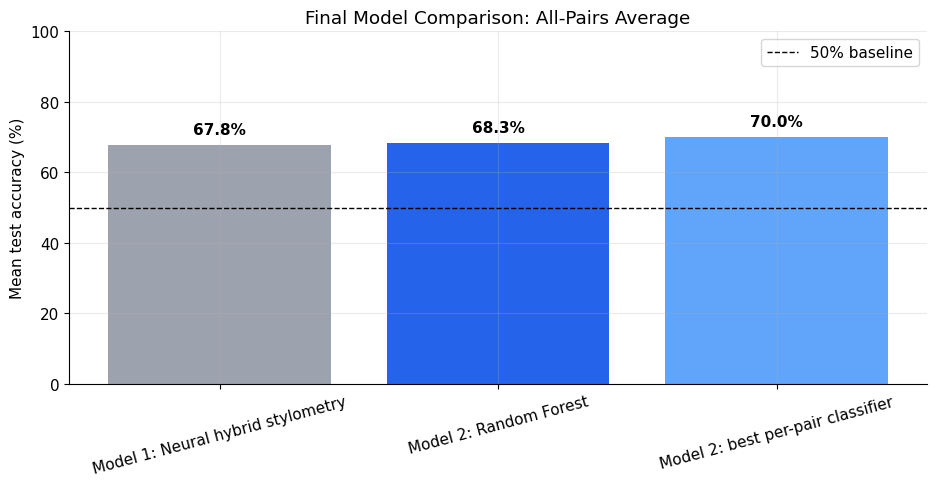

In [25]:
fig, ax = plt.subplots(figsize=(9.5, 5))

colors = ["#9ca3af", "#2563eb", "#60a5fa"][:len(comparison)]
values = comparison["reported_test_acc"] * 100

bars = ax.bar(comparison["model"], values, color=colors)

ax.axhline(50, color="black", linestyle="--", linewidth=1, label="50% baseline")

for bar, value in zip(bars, values):
    ax.annotate(
        f"{value:.1f}%",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="black",
    )

ax.set_ylabel("Mean test accuracy (%)")
ax.set_title("Final Model Comparison: All-Pairs Average")
ax.set_ylim(0, max(100, values.max() + 8))
ax.tick_params(axis="x", rotation=15)
ax.legend()

fig.tight_layout()
fig.savefig(FIG / "final_workflow_model_comparison.png", dpi=200)
plt.show()


## 12. Final Interpretation

A careful final claim:

```text
The neural stylometry model was inspired by prior behavioral-stylometry work in chess. It uses padded whole-game board tensors and a Transformer-based sequence encoder, but on this small dataset it did not outperform simpler approaches.

The strongest final result is the controlled style-trajectory classifier. It compares human and Stockfish continuations from the same midgame FENs and uses board-evaluation trajectory rather than direct Stockfish top-move agreement.
```

The cheating concern is addressed by using `style_trajectory`, not `engine_agreement`, as the final feature set.